# Задача 4.16
# Монте Карло для двух точек в эллипсе

## Условие
Внутри эллипса $(u/23)^2+(v/6)^2\le1$ независимо выбираются две равномерные точки. A — расстояние между ними меньше 9.2; B — обе координаты первой положительны, обе координаты второй отрицательны. По $100000$ парам оценить $P(A)$ и $P(A\mid B)$.

## Теория с нуля и решение вручную
### 1. Как получить равномерную точку
Из равномерной точки единичного диска $(X,Y)$ получаем $(u,v)=(23X,6Y)$. Линейное преобразование увеличивает все малые площади в одинаковое число $23\cdot6=138$ раз, поэтому равномерность сохраняется. Площадь эллипса $138\pi$.
Для диска выбираем $R=\sqrt U$, $\Theta=2\pi V$, где $U,V$ независимы и равномерны на $[0,1]$. Тогда
$$u=23\sqrt U\cos(2\pi V),\qquad v=6\sqrt U\sin(2\pi V).$$
Квадратный корень нужен потому, что площадь круга радиуса $r$ пропорциональна $r^2$. Равномерный радиус дал бы слишком много точек возле центра. Равномерные координаты ограничивающего прямоугольника без отбраковки точек тоже не годятся.

### 2. Условия событий
$$A=\{(u_1-u_2)^2+(v_1-v_2)^2<9.2^2\},$$
$$B=\{u_1>0,v_1>0,u_2<0,v_2<0\}.$$
Из симметрии каждый квадрант имеет четверть площади. Независимость двух точек даёт $P(B)=1/16$. Поэтому среди 100000 пар ожидается около 6250 пар с условием B, а не 100000. Условная оценка обычно менее точна из-за меньшего знаменателя.

### 3. Ручное описание решения
Без компьютера точная вероятность задаётся отношением четырёхмерных объёмов. Пусть $E$ — эллипс, $S=138\pi$, $Q_+$ и $Q_-$ — его части в первом и третьем квадрантах:
$$P(A)=\frac1{S^2}\int_E\int_E\mathbf1\{\|z_1-z_2\|<9.2\}\,dz_2\,dz_1,$$
$$P(A\mid B)=\frac{16}{S^2}\int_{Q_+}\int_{Q_-}\mathbf1\{\|z_1-z_2\|<9.2\}\,dz_2\,dz_1.$$
Символ $\mathbf1$ означает индикатор: 1 внутри нужной области, 0 снаружи. Эти формулы объясняют, что именно приближает Монте Карло. В задаче требуется численное решение; простой обязательной формулы из элементарных функций здесь нет. Ожидаемые ориентиры — около 0.35 и 0.07, а не точные ответы, одинаковые в каждом запуске.

### 4. Проверки и округление
Все точки должны удовлетворять неравенству эллипса; частота B должна быть около $1/16$. В конце покажем оба формата округления из-за противоречия текста и примеров листка. Для вероятностей около 0.35 округление до одного знака особенно грубо: небольшие изменения оценки могут менять отображаемое значение около границы 0.35.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

Все точки внутри эллипса: True
Частота B: 0.06374 ; теория: 0.0625
A: расстояние меньше 9.2: успехов 35006, знаменатель 100000
  частота = 0.35006000; ориентир 95%: [0.34710359; 0.35301641]


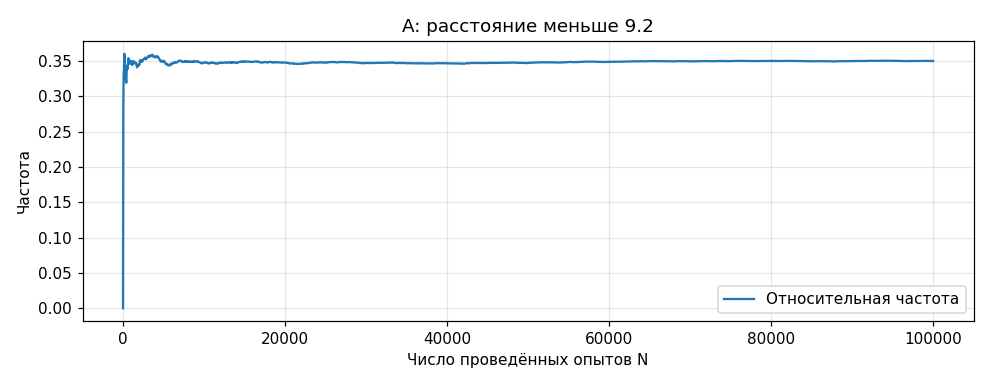

A при условии противоположных квадрантов B: успехов 414, знаменатель 6374
  частота = 0.06495136; ориентир 95%: [0.05890128; 0.07100145]


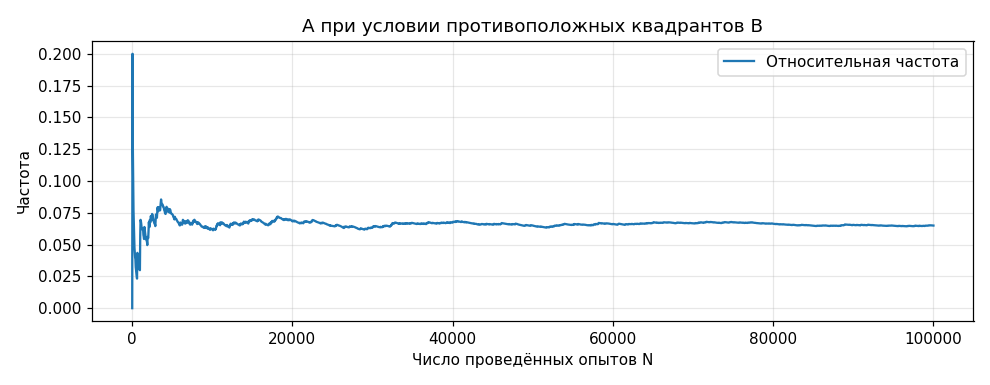

P(A): два знака 0.35; один знак 0.4
P(A|B): два знака 0.06; один знак 0.1


In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

N = 100_000
def point_in_ellipse(size):
    radius = np.sqrt(rng.random(size))
    angle = 2*math.pi*rng.random(size)
    return 23*radius*np.cos(angle), 6*radius*np.sin(angle)
u1,v1 = point_in_ellipse(N)
u2,v2 = point_in_ellipse(N)
A = (u1-u2)**2+(v1-v2)**2 < 9.2**2
B = (u1 > 0) & (v1 > 0) & (u2 < 0) & (v2 < 0)
print('Все точки внутри эллипса:',
      np.all((u1/23)**2+(v1/6)**2 <= 1+1e-12) and
      np.all((u2/23)**2+(v2/6)**2 <= 1+1e-12))
print('Частота B:', np.mean(B), '; теория:', 1/16)
pA = report(A, 'A: расстояние меньше 9.2')
pAB = report(A, 'A при условии противоположных квадрантов B', condition=B)
for name,value in [('P(A)',pA),('P(A|B)',pAB)]:
    print(f'{name}: два знака {value:.2f}; один знак {value:.1f}')
